In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)



In [4]:
# Load the bank transaction dataset

df = pd.read_csv("creditcard.csv")

# Display first five records

print(df.head())

# Dataset information

print("Dataset Shape:", df.shape)

# Check missing values

print("Missing Values:", df.isnull().sum().sum())

# Count normal and fraudulent transactions

print("\nTransaction Distribution:")
print(df['Class'].value_counts())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

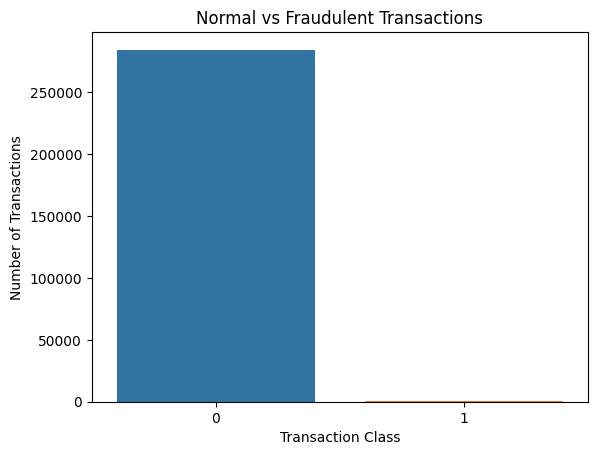

In [5]:
sns.countplot(x='Class', data=df)

plt.title("Normal vs Fraudulent Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Number of Transactions")

plt.show()

In [6]:
# Separate features and target

X = df.drop('Class', axis=1)

y = df['Class']

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (284807, 30)
Labels shape: (284807,)


In [7]:
# Split dataset

X_train_all, X_test, y_train_all, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train_all.shape)
print("Testing data:", X_test.shape)

Training data: (227845, 30)
Testing data: (56962, 30)


In [8]:
# Select only normal transactions from training data

X_train_normal = X_train_all[y_train_all == 0]

# Divide normal training data into training and validation

X_train_normal, X_val_normal = train_test_split(
    X_train_normal,
    test_size=0.2,
    random_state=42
)

print("Normal training data:", X_train_normal.shape)
print("Normal validation data:", X_val_normal.shape)

Normal training data: (181960, 30)
Normal validation data: (45491, 30)


In [9]:
# Standardize the transaction features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_normal)

X_val_scaled = scaler.transform(X_val_normal)

X_test_scaled = scaler.transform(X_test)

print("Data preprocessing completed")

Data preprocessing completed


In [10]:
# Define input dimension

input_dim = X_train_scaled.shape[1]

# Input layer

input_layer = Input(shape=(input_dim,))

# Encoder

encoder = Dense(16, activation='relu')(input_layer)

latent = Dense(8, activation='relu')(encoder)

# Decoder

decoder = Dense(16, activation='relu')(latent)

output_layer = Dense(input_dim, activation='linear')(decoder)

# Create Autoencoder model

autoencoder = Model(
    inputs=input_layer,
    outputs=output_layer
)

# Display model architecture

autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 16)                  │             496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             144 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 30)                  │             510 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Compile Autoencoder

autoencoder.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("Model compiled successfully")

Model compiled successfully


In [12]:
# Train only using normal transactions

history = autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=20,
    batch_size=256,
    shuffle=True,
    validation_data=(X_val_scaled, X_val_scaled)
)

Epoch 1/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - loss: 0.8962 - mae: 0.6399 - val_loss: 0.6740 - val_mae: 0.5498
Epoch 2/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.6422 - mae: 0.5377 - val_loss: 0.5833 - val_mae: 0.5087
Epoch 3/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5626 - mae: 0.5023 - val_loss: 0.5549 - val_mae: 0.4950
Epoch 4/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5466 - mae: 0.4903 - val_loss: 0.5221 - val_mae: 0.4812
Epoch 5/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5324 - mae: 0.4814 - val_loss: 0.5068 - val_mae: 0.4734
Epoch 6/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5107 - mae: 0.4721 - val_loss: 0.4962 - val_mae: 0.4662
Epoch 7/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.5003 - mae: 0.4661 - val_loss: 0.4857 - val_mae: 0.4593
Epoch 8/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.4809 - mae: 0.4571 - val_loss: 0.4776 - val_mae: 0.4527
Epoch 9/20
711/711 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - lo

In [13]:
X_train_scaled, X_train_scaled

(array([[-1.11926954,  0.60492486,  0.10010614, ...,  0.0865059 ,
          0.04169953, -0.34565878],
        [ 0.63908625,  0.95787023, -0.18677897, ..., -0.04596651,
         -0.05319438,  0.00752762],
        [ 1.29607284, -0.79886897, -0.47851656, ..., -0.01507148,
          0.30809264,  0.56884673],
        ...,
        [ 0.96821098, -0.15772358,  0.23629475, ...,  0.28633832,
          0.48901673, -0.3074656 ],
        [-0.94857173, -0.31840092,  0.8530962 , ..., -0.20995115,
         -0.07343186, -0.34967912],
        [ 1.38274776,  0.01441773,  0.54355112, ...,  0.61643729,
          0.30899062, -0.34650305]], shape=(181960, 30)),
 array([[-1.11926954,  0.60492486,  0.10010614, ...,  0.0865059 ,
          0.04169953, -0.34565878],
        [ 0.63908625,  0.95787023, -0.18677897, ..., -0.04596651,
         -0.05319438,  0.00752762],
        [ 1.29607284, -0.79886897, -0.47851656, ..., -0.01507148,
          0.30809264,  0.56884673],
        ...,
        [ 0.96821098, -0.15772358,

In [14]:
# Evaluate validation reconstruction

val_loss, val_mae = autoencoder.evaluate(
    X_val_scaled,
    X_val_scaled
)

print("Validation Loss:", val_loss)
print("Validation MAE:", val_mae)

1422/1422 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.4407 - mae: 0.4179
Validation Loss: 0.44901877641677856
Validation MAE: 0.4175737202167511


In [16]:
# Predict reconstructed validation transactions

val_predictions = autoencoder.predict(X_val_scaled)

# Calculate reconstruction error

val_errors = np.mean(
    np.square(X_val_scaled - val_predictions),
    axis=1
)

# Set anomaly threshold

threshold = np.percentile(val_errors, 99.5)

print("Anomaly Threshold:", threshold)

1422/1422 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Anomaly Threshold: 5.673044014975812


In [17]:
# Reconstruct test transactions

test_predictions = autoencoder.predict(X_test_scaled)

# Calculate reconstruction errors

test_errors = np.mean(
    np.square(X_test_scaled - test_predictions),
    axis=1
)

# Classify transactions

y_pred = (test_errors > threshold).astype(int)

print("Anomaly detection completed")

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Anomaly detection completed


Accuracy: 99.4364664162073 %
Precision: 0.18233618233618235
Recall: 0.6530612244897959
F1 Score: 0.28507795100222716
ROC-AUC: 0.9416332057583867

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.18      0.65      0.29        98

    accuracy                           0.99     56962
   macro avg       0.59      0.82      0.64     56962
weighted avg       1.00      0.99      1.00     56962



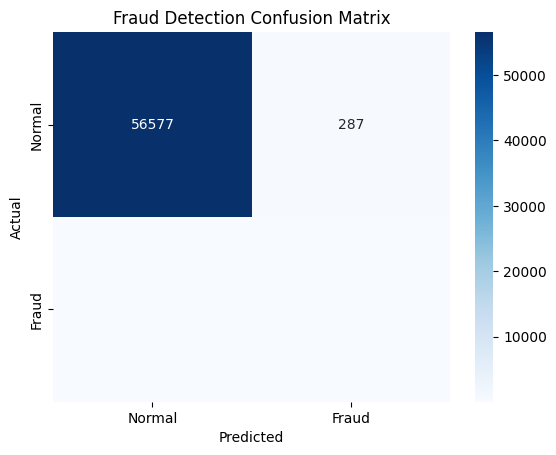

In [18]:
# Calculate performance metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, test_errors)

print("Accuracy:", accuracy * 100, "%")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

# Classification report

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion matrix

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Fraud'],
    yticklabels=['Normal', 'Fraud']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Fraud Detection Confusion Matrix")

plt.show()

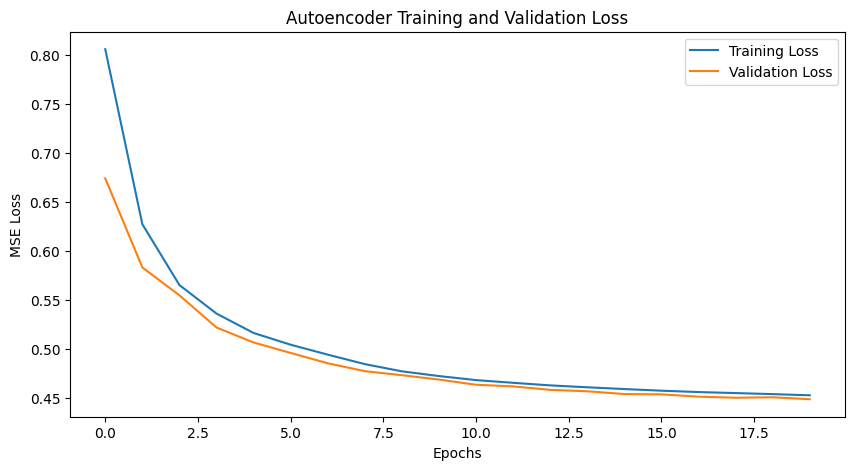

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Autoencoder Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")

plt.legend()
plt.show()

In [23]:
# Select one test transaction

index = 1

transaction_error = test_errors[index]

actual = int(y_test.iloc[index])

predicted = int(y_pred[index])

print("Actual Class:", actual)
print("Predicted Class:", predicted)

print("Reconstruction Error:", transaction_error)

if predicted == 1:
    print("Result: Potential Fraud Transaction")
else:
    print("Result: Normal Transaction")

Actual Class: 0
Predicted Class: 0
Reconstruction Error: 0.6730904367111141
Result: Normal Transaction
